# Laboratorium 4 — CNN: splotowe sieci dla obrazów

**Cel:** zbudować pierwszą sieć splotową (CNN) i pokazać jej przewagę nad MLP na tym samym zbiorze (CIFAR-10). Porównamy accuracy, liczbę parametrów i czas uczenia.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 0. Instalacja zależności

In [1]:
!pip install torch torchvision matplotlib

## Import bibliotek i wybór urządzenia

W Colab: **Runtime → Change runtime type → GPU** (CNN najlepiej trenować na GPU).

In [2]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu128 | urządzenie: cuda


## 1. Dane: CIFAR-10

CIFAR-10 to 60 000 kolorowych obrazów 32×32 w 10 klasach (samolot, samochód, ptak, kot, ...). Kolor oznacza **3 kanały** wejścia — inaczej niż FashionMNIST.

100%|██████████| 170M/170M [47:50<00:00, 59.4kB/s]


Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 50000 | Test: 10000


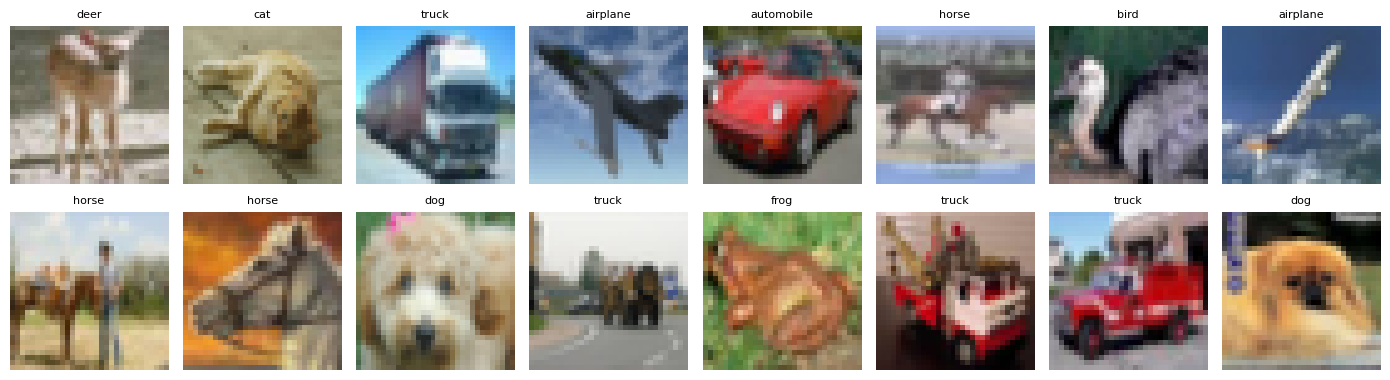

In [3]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

train_ds = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)

import numpy as np
mean_t = torch.tensor(mean).view(3,1,1); std_t = torch.tensor(std).view(3,1,1)
xb, yb = next(iter(train_dl))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow((img*std_t + mean_t).clamp(0,1).permute(1,2,0).numpy())
    ax.set_title(classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Dwa modele: MLP i CNN

**MLP** spłaszcza obraz do wektora 3072 (=32·32·3). **CNN** używa bloków splot–ReLU–pooling, zachowując strukturę przestrzenną. Porównamy ich liczbę parametrów.

In [4]:
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )
    def forward(self, x): return self.net(x)

class SimpleCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64))  # 32x32 -> 8x8
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64*8*8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes),
        )
    def forward(self, x): return self.classifier(self.features(x))

def count_params(m): return sum(p.numel() for p in m.parameters())
print("Parametry MLP:", f"{count_params(MLP()):,}")
print("Parametry CNN:", f"{count_params(SimpleCNN()):,}")

Parametry MLP: 1,707,274
Parametry CNN: 1,117,354


## 3. Funkcja treningu z pomiarem czasu

Ta sama funkcja dla obu modeli — uczciwe porównanie. Zwraca historię i czas uczenia.

In [5]:
def evaluate(model, dl):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item(); total += yb.numel()
    return correct/total

def train_model(model, epochs=10, lr=1e-3):
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    accs = []
    t0 = time.time()
    for epoch in range(1, epochs+1):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        acc = evaluate(model, test_dl); accs.append(acc)
        print(f"  epoka {epoch:2d} | accuracy test {acc*100:.2f}%")
    dt = time.time() - t0
    return accs, dt

## 4. Trening: MLP vs CNN

Oba modele uczymy tyle samo epok, tym samym optymalizatorem.

In [6]:
EPOCHS = 10
print("== MLP ==")
mlp = MLP()
acc_mlp, t_mlp = train_model(mlp, EPOCHS)
print("\n== CNN ==")
cnn = SimpleCNN()
acc_cnn, t_cnn = train_model(cnn, EPOCHS)

== MLP ==
  epoka  1 | accuracy test 46.50%
  epoka  2 | accuracy test 48.89%
  epoka  3 | accuracy test 50.66%
  epoka  4 | accuracy test 51.59%
  epoka  5 | accuracy test 52.92%
  epoka  6 | accuracy test 53.47%
  epoka  7 | accuracy test 52.00%
  epoka  8 | accuracy test 52.85%
  epoka  9 | accuracy test 54.14%
  epoka 10 | accuracy test 53.72%

== CNN ==
  epoka  1 | accuracy test 60.86%
  epoka  2 | accuracy test 69.94%
  epoka  3 | accuracy test 70.83%
  epoka  4 | accuracy test 74.54%
  epoka  5 | accuracy test 77.02%
  epoka  6 | accuracy test 77.01%
  epoka  7 | accuracy test 78.67%
  epoka  8 | accuracy test 78.50%
  epoka  9 | accuracy test 79.60%
  epoka 10 | accuracy test 78.29%


## 5. Porównanie

Zestawienie liczby parametrów, najlepszej accuracy i czasu uczenia oraz krzywe accuracy.

model  |    parametry |  best acc |  czas [s]
----------------------------------------------
MLP    |    1,707,274 |    54.14% |     137.5
CNN    |    1,117,354 |    79.60% |     150.9


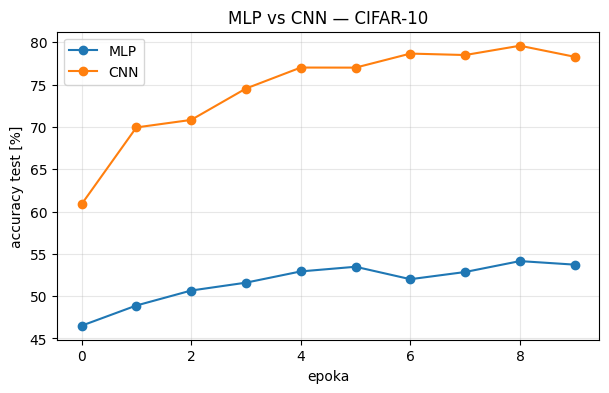

In [7]:
print(f"{'model':6} | {'parametry':>12} | {'best acc':>9} | {'czas [s]':>9}")
print('-'*46)
print(f"{'MLP':6} | {count_params(mlp):>12,} | {max(acc_mlp)*100:>8.2f}% | {t_mlp:>9.1f}")
print(f"{'CNN':6} | {count_params(cnn):>12,} | {max(acc_cnn)*100:>8.2f}% | {t_cnn:>9.1f}")

plt.figure(figsize=(7,4))
plt.plot([a*100 for a in acc_mlp], "o-", label="MLP")
plt.plot([a*100 for a in acc_cnn], "o-", label="CNN")
plt.xlabel("epoka"); plt.ylabel("accuracy test [%]"); plt.legend(); plt.title("MLP vs CNN — CIFAR-10")
plt.grid(alpha=0.3); plt.show()

## 6. Co „widzi" pierwsza warstwa CNN

Przepuśćmy jeden obraz przez pierwszą warstwę splotową i podejrzyjmy kilka **map cech** — to odpowiedzi filtrów na wzorce w obrazie.

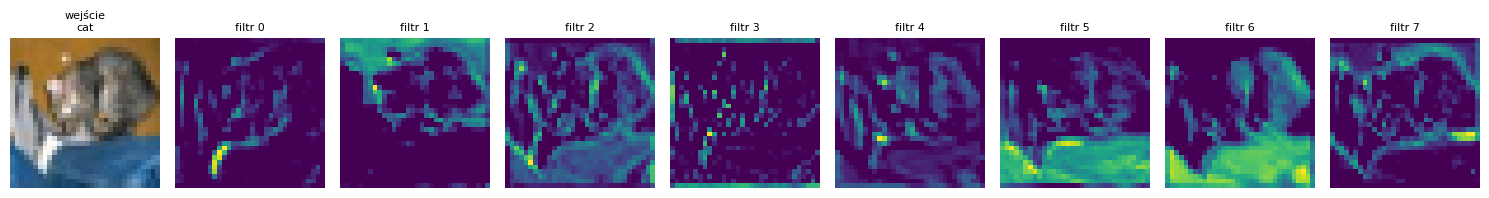

In [8]:
img, label = test_ds[0]
first_conv = cnn.features[0][0]  # pierwsza nn.Conv2d
with torch.no_grad():
    fmaps = torch.relu(first_conv(img.unsqueeze(0).to(device)))[0].cpu()

fig, axes = plt.subplots(1, 9, figsize=(15, 2.4))
axes[0].imshow((img*std_t + mean_t).clamp(0,1).permute(1,2,0).numpy())
axes[0].set_title(f"wejście\n{classes[label]}", fontsize=8); axes[0].axis("off")
for i, ax in enumerate(axes[1:]):
    ax.imshow(fmaps[i], cmap="viridis"); ax.set_title(f"filtr {i}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Podsumowanie

- MLP na obrazach ma dużo parametrów i ignoruje strukturę przestrzenną.
- CNN dzięki lokalności, współdzieleniu wag i hierarchii cech osiąga **wyższą accuracy** — często przy **mniejszej** liczbie parametrów.
- Pierwsze warstwy wykrywają proste wzorce (krawędzie, kolory), głębsze — złożone.
- Warstwy splotowe rozbierzemy szczegółowo na zajęciach 5, pooling na zajęciach 6.

**Zadanie na sprawozdanie:** zobacz `zadanie.md`.

---
*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*